# T2 · Nurse-led chest-pain rule-out — Capstone prototype
**3099704 AI for Digital Health · Capstone, 18 October 2026**

Question: *Can a nurse, using only what is known at triage, safely identify outpatients with stable chest pain who do not need urgent cardiology referral?*

Data: UCI Heart Disease (Cleveland, plus Hungary, VA Long Beach and Switzerland for external validation). Public, de-identified data only.

> AI-assistant use: Claude (Anthropic) helped draft code and text. The group reviewed, ran and is responsible for every result.

## 0 · Project canvas
| # | Item | Our answer |
|---|---|---|
| 1 | **Problem** | Stable chest-pain outpatients queue for cardiology review; many have no significant coronary disease. Queues delay the patients who do. |
| 2 | **User** | Triage nurse in a cardiology / medicine OPD. |
| 3 | **Decision & moment of use** | At triage, before any test: *refer for cardiology work-up* vs *routine follow-up*. |
| 4 | **Is AI needed?** | Simpler alternative = a two-item rule (chest-pain type + age). This is our baseline; ML must beat it. |
| 5 | **Task** | age, sex, chest-pain type, resting BP → probability of angiographic CAD (≥50 % narrowing). |
| 6 | **Dataset** | UCI Heart Disease, CC BY 4.0. Cleveland n = 303 for development; 1 row = 1 patient referred for angiography. |
| 7 | **Label** | `num > 0` on angiography. Bias: only patients already sent for angiography were labelled (verification / referral bias); prevalence 46 %. |
| 8 | **Index time / legal features** | Triage. Legal: age, sex, cp, trestbps (± resting ECG). **Illegal:** exercise-test features, `ca` (fluoroscopy), `thal` (thallium scan) — they happen after the decision. |
| 9 | **Baseline** | Rule: *rule out if chest pain is atypical or non-anginal AND age < 55*; otherwise refer. |
| 10 | **Primary metric** | % of patients ruled out at **sensitivity ≥ 95 %** (workload saved without missing > 5 % of disease); report NPV. Threshold set on training data only. |
| 11 | **Key risk** | Missed CAD (false reassurance); shift to other sites; women under-represented; NOT for acute chest pain (needs ECG + troponin). |
| 12 | **Demo case** | A 48-year-old woman with atypical chest pain, BP 130 → low risk; a 60-year-old man, asymptomatic, BP 140 → refer. |

Scope: **stable** chest pain only. Acute chest pain is out of scope and must follow the ACS pathway.

In [1]:
import warnings, os, urllib.request
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from IPython.display import display
pd.set_option("display.width", 140); pd.set_option("display.precision", 3)
SEED = 42
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10, "figure.dpi": 110})
os.makedirs("figs", exist_ok=True)

## 1 · Load data
Put the unzipped `heartdisease/` folder next to this notebook. If it is missing, the files are downloaded from the UCI repository.
Note the `WARNING` file in the archive: the raw `cleveland.data` is corrupted, so we use **`processed.cleveland.data`**.

In [2]:
DATA_DIR = "heartdisease"
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
COLS = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
SITES = {"Cleveland": "cleveland", "Hungary": "hungarian", "VA Long Beach": "va", "Switzerland": "switzerland"}

def load(site):
    path = os.path.join(DATA_DIR, f"processed.{SITES[site]}.data")
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        urllib.request.urlretrieve(URL + f"processed.{SITES[site]}.data", path)
    d = pd.read_csv(path, header=None, names=COLS, na_values="?")
    d["y"] = (d["num"] > 0).astype(int)          # label: any angiographic CAD
    d["site"] = site
    return d

raw = {s: load(s) for s in SITES}
for s, d in raw.items():
    print(f"{s:14s} n={len(d):3d}  CAD prevalence={d.y.mean():.0%}")

Cleveland      n=303  CAD prevalence=46%
Hungary        n=294  CAD prevalence=36%
VA Long Beach  n=200  CAD prevalence=74%
Switzerland    n=123  CAD prevalence=93%


## 2 · Data audit — find the traps

In [3]:
cl = raw["Cleveland"].copy()
print("Original label `num` (0 = no CAD, 1-4 = severity):", cl.num.value_counts().sort_index().to_dict())
print("Duplicate rows:", cl.duplicated().sum())
print("\nMissing values ('?') per site, % of rows:")
miss = pd.DataFrame({s: d[COLS[:-1]].isna().mean()*100 for s, d in raw.items()}).round(0)
print(miss[miss.sum(axis=1) > 0])
print("\nHidden missing: cholesterol recorded as 0")
print({s: int((d.chol == 0).sum()) for s, d in raw.items()})

Original label `num` (0 = no CAD, 1-4 = severity): {0: 164, 1: 55, 2: 36, 3: 35, 4: 13}
Duplicate rows: 0

Missing values ('?') per site, % of rows:
          Cleveland  Hungary  VA Long Beach  Switzerland
trestbps        0.0      0.0           28.0          2.0
chol            0.0      8.0            4.0          0.0
fbs             0.0      3.0            4.0         61.0
restecg         0.0      0.0            0.0          1.0
thalach         0.0      0.0           26.0          1.0
exang           0.0      0.0           26.0          1.0
oldpeak         0.0      0.0           28.0          5.0
slope           0.0     65.0           51.0         14.0
ca              1.0     99.0           99.0         96.0
thal            1.0     90.0           83.0         42.0

Hidden missing: cholesterol recorded as 0
{'Cleveland': 0, 'Hungary': 0, 'VA Long Beach': 49, 'Switzerland': 123}


**Trap 1, zeros that mean "not measured".** In Switzerland, cholesterol is 0 for every patient, and in VA for 49. We recode `chol == 0` as missing. `ca` and `thal` are almost entirely missing outside Cleveland, so a model that needs them could not be used at other sites anyway.

**`restecg` is collapsed to binary** (0 = normal, 1 = abnormal) across all sites: only 1 Cleveland patient has ST-T abnormality (code 1), so a one-hot dummy for it would just memorize noise; this matches `model/train_tiered_models.py`.

In [ ]:
for d in raw.values():
    d.loc[d.chol == 0, "chol"] = np.nan

# restecg collapsed to binary before any modeling (matches model/train_tiered_models.py)
for d in [cl] + list(raw.values()):
    d["restecg"] = (d["restecg"] > 0).astype(int)   # collapse ST-T(1)+LVH(2) → abnormal (only 1 Cleveland patient has ST-T)

CP = {1: "typical angina", 2: "atypical angina", 3: "non-anginal", 4: "asymptomatic"}
t = cl.groupby("cp").y.agg(n="size", CAD_rate="mean").rename(index=CP)
print(t, "\n")
print(cl.groupby(cl.sex.map({0: "female", 1: "male"})).y.agg(n="size", CAD_rate="mean"))

**Trap 2, referral (verification) bias.** Everyone here was already sent for angiography, so prevalence is 46 %, far above a real triage population.
The "asymptomatic" group has the **highest** CAD rate (73 %). An asymptomatic person was referred only because something else was already suspicious.
The model learns *who gets referred*, not only *who has disease*.

**Trap 3, subgroups.** Only 97 women; CAD rate 26 % vs 55 % in men. We report sensitivity separately by sex.

## 3 · Index time: which features are legal?
| Tier | Features | Available when? | Legal at triage? |
|---|---|---|---|
| A | age, sex, cp, trestbps | history + BP cuff | ✅ |
| B | + restecg | resting ECG | ✅ (if ECG at triage) |
| C | + chol, fbs | blood test | ⚠️ often not yet |
| D | + thalach, exang, oldpeak, slope | **exercise stress test** | ❌ after decision |
| E | + ca, thal | **fluoroscopy, thallium scan** (≈ $100 each in the UCI cost file) | ❌ after decision |

In [5]:
TIERS = {
    "A  triage (age, sex, cp, BP)": ["age","sex","cp","trestbps"],
    "B  + resting ECG":            ["age","sex","cp","trestbps","restecg"],
    "C  + chol, fbs":              ["age","sex","cp","trestbps","restecg","chol","fbs"],
    "D  + exercise test":          ["age","sex","cp","trestbps","restecg","chol","fbs","thalach","exang","oldpeak","slope"],
    "E  + ca, thal (all 13)":      ["age","sex","cp","trestbps","restecg","chol","fbs","thalach","exang","oldpeak","slope","ca","thal"],
}
TRIAGE = TIERS["A  triage (age, sex, cp, BP)"]
CAT = ["cp","restecg","slope","thal"]

def make_model(cols, kind="lr"):
    pre = ColumnTransformer([
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), [c for c in cols if c in CAT]),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), [c for c in cols if c not in CAT])])
    clf = LogisticRegression(max_iter=2000) if kind == "lr" else RandomForestClassifier(300, min_samples_leaf=5, random_state=SEED)
    return make_pipeline(pre, clf)

def baseline_rule(d):
    # 1 = refer, 0 = rule out.  Rule out only if chest pain is atypical/non-anginal AND age < 55
    return (~(d.cp.isin([2, 3]) & (d.age < 55))).astype(int).values

## 4 · Split: seal the test set
Cleveland → 75 % development / 25 % **sealed test** (stratified, split by patient; no duplicates exist).
All tuning and the threshold choice use cross-validation on the development set only. The test set is used **once**, in section 7.

In [6]:
dev, test = train_test_split(cl, test_size=0.25, stratify=cl.y, random_state=SEED)
print(f"development n={len(dev)} (CAD {dev.y.mean():.0%})   sealed test n={len(test)} (CAD {test.y.mean():.0%})")
y_dev = dev.y.values

def oof(cols, kind="lr", seed=0):
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)   # file order matters → always shuffle
    return cross_val_predict(make_model(cols, kind), dev[cols], y_dev, cv=cv, method="predict_proba")[:, 1]

def threshold_for_sens(y, p, target=0.95):
    # highest threshold whose sensitivity is still >= target (refer if p >= thr)
    best = p.min()
    for thr in np.unique(p):
        if y[p >= thr].sum() / y.sum() >= target:
            best = thr
    return best

def rule_out_metrics(y, refer):
    refer = np.asarray(refer).astype(bool)
    tp = (refer & (y == 1)).sum(); fn = (~refer & (y == 1)).sum(); tn = (~refer & (y == 0)).sum()
    return dict(sensitivity=tp / (tp + fn), ruled_out=(~refer).mean(),
                NPV=tn / (tn + fn) if (tn + fn) else np.nan, missed_per_100=100 * fn / len(y))

development n=227 (CAD 46%)   sealed test n=76 (CAD 46%)


## 5 · Is AI needed? Baseline vs models (repeated 5-fold CV on the development set)

In [7]:
rows = []
r = rule_out_metrics(y_dev, baseline_rule(dev))
rows.append(dict(model="Baseline rule (cp + age)", AUROC=np.nan, **r))
for name, cols, kind in [("LR · tier A triage", TRIAGE, "lr"), ("RF · tier A triage", TRIAGE, "rf")]:
    aucs, mets = [], []
    for s in range(10):
        p = oof(cols, kind, s)
        aucs.append(roc_auc_score(y_dev, p))
        mets.append(rule_out_metrics(y_dev, p >= threshold_for_sens(y_dev, p)))
    m = pd.DataFrame(mets).mean()
    rows.append(dict(model=name, AUROC=f"{np.mean(aucs):.3f} ± {np.std(aucs):.3f}", **m.to_dict()))
cmp = pd.DataFrame(rows).set_index("model")
cmp[["sensitivity","ruled_out","NPV"]] = cmp[["sensitivity","ruled_out","NPV"]].astype(float).round(2)
cmp["missed_per_100"] = cmp["missed_per_100"].astype(float).round(1)
cmp

,AUROC,sensitivity,ruled_out,NPV,missed_per_100
model,,,,,
Baseline rule (cp + age),NaN,0.96,0.25,0.93,1.8
LR · tier A triage,0.834 ± 0.004,0.95,0.21,0.90,2.2
RF · tier A triage,0.827 ± 0.007,0.95,0.26,0.92,2.2


**Reading.** At the operating point that matters (sensitivity ≥ 95 %), the models rule out about the same share of patients as the two-item rule.
RF is not better than LR. We keep **logistic regression on tier A**: transparent, four inputs, no gain from more complexity.

## 6 · Leakage demo: what if we used features from *after* the decision?

                        tier  AUROC    sd
A  triage (age, sex, cp, BP)  0.834 0.004
            B  + resting ECG  0.838 0.003
              C  + chol, fbs  0.836 0.004
          D  + exercise test  0.847 0.006
      E  + ca, thal (all 13)  0.891 0.006


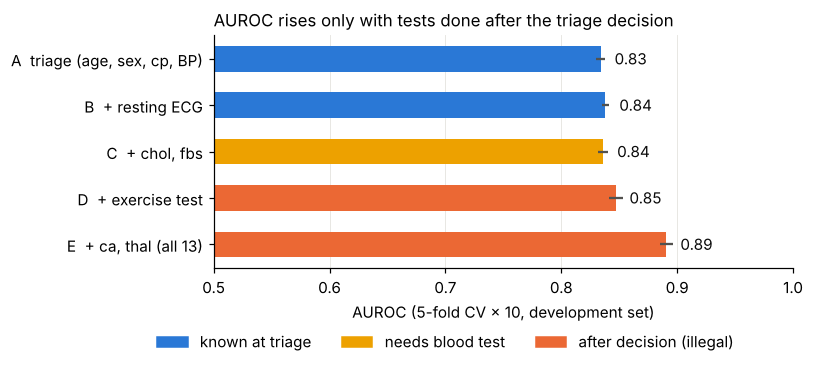

In [8]:
lk = []
for name, cols in TIERS.items():
    a = [roc_auc_score(y_dev, oof(cols, "lr", s)) for s in range(10)]
    lk.append((name, np.mean(a), np.std(a)))
lk = pd.DataFrame(lk, columns=["tier", "AUROC", "sd"]); print(lk.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
colors = [BLUE, BLUE, YELLOW, ORANGE, ORANGE]
ax.barh(lk.tier[::-1], lk.AUROC[::-1], color=colors[::-1], height=0.55, xerr=lk.sd[::-1], ecolor="#52514e")
for i, v in enumerate(lk.AUROC[::-1]):
    ax.text(v + 0.012, i, f"{v:.2f}", va="center", color="#0b0b0b")
ax.set_xlim(0.5, 1.0); ax.set_xlabel("AUROC (5-fold CV × 10, development set)")
ax.set_title("AUROC rises only with tests done after the triage decision", loc="left", fontsize=11)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="known at triage"), Patch(color=YELLOW, label="needs blood test"),
                   Patch(color=ORANGE, label="after decision (illegal)")], loc="upper center", bbox_to_anchor=(0.4, -0.22), ncol=3, frameon=False)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.savefig("figs/leakage_tiers.png", dpi=200); plt.show()

Published Cleveland results (AUROC ≈ 0.90) use `ca` and `thal`, which come from fluoroscopy and a thallium scan.
At triage those numbers do not exist yet, so the honest figure is ≈ 0.84.

## 7 · Final model: fix the threshold on development, open the sealed test once

In [9]:
final = make_model(TRIAGE, "lr").fit(dev[TRIAGE], y_dev)
p_oof = np.mean([oof(TRIAGE, "lr", s) for s in range(10)], axis=0)
THR = threshold_for_sens(y_dev, p_oof, 0.95)
print(f"Threshold chosen on development CV: refer if predicted risk ≥ {THR:.3f}")

# ---- the one and only look at the sealed test set ----
y_te = test.y.values
p_te = final.predict_proba(test[TRIAGE])[:, 1]
rng = np.random.default_rng(SEED)
def boot(fn, B=2000):
    vals = []
    for _ in range(B):
        i = rng.integers(0, len(y_te), len(y_te))
        if y_te[i].min() == y_te[i].max(): continue
        vals.append(fn(i))
    return np.nanpercentile(vals, [2.5, 97.5])

res = {}
for name, refer in [("Baseline rule", baseline_rule(test)), ("LR tier A", (p_te >= THR).astype(int))]:
    m = rule_out_metrics(y_te, refer)
    lo_hi = {k: boot(lambda i, k=k: rule_out_metrics(y_te[i], refer[i])[k]) for k in ["sensitivity", "ruled_out", "NPV"]}
    res[name] = {k: f"{m[k]:.2f} [{lo_hi[k][0]:.2f}–{lo_hi[k][1]:.2f}]" for k in lo_hi} | {"missed_per_100": round(m["missed_per_100"], 1)}
auc_te = roc_auc_score(y_te, p_te); ci = boot(lambda i: roc_auc_score(y_te[i], p_te[i]))
res["LR tier A"]["AUROC"] = f"{auc_te:.2f} [{ci[0]:.2f}–{ci[1]:.2f}]"; res["Baseline rule"]["AUROC"] = "–"
pd.DataFrame(res).T

Threshold chosen on development CV: refer if predicted risk ≥ 0.162


,sensitivity,ruled_out,NPV,missed_per_100,AUROC
Baseline rule,0.91 [0.81–1.00],0.30 [0.21–0.41],0.87 [0.71–1.00],3.9,–
LR tier A,0.97 [0.90–1.00],0.29 [0.20–0.39],0.95 [0.84–1.00],1.3,0.84 [0.74–0.93]


With n = 76 the confidence intervals are wide. The test set confirms the CV picture but cannot separate the model from the rule.

### Workload vs safety: choosing the threshold from capacity and harm

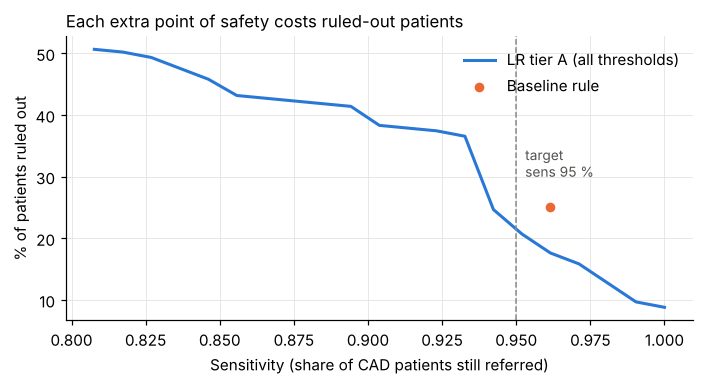

In [10]:
sens_grid = np.linspace(0.80, 1.0, 41)
curve = []
for t in sens_grid:
    thr = threshold_for_sens(y_dev, p_oof, t)
    curve.append(rule_out_metrics(y_dev, p_oof >= thr))
curve = pd.DataFrame(curve)
rb = rule_out_metrics(y_dev, baseline_rule(dev))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(curve.sensitivity, curve.ruled_out * 100, color=BLUE, lw=2, label="LR tier A (all thresholds)")
ax.scatter([rb["sensitivity"]], [rb["ruled_out"] * 100], s=70, color=ORANGE, zorder=3, edgecolor="white", linewidth=2, label="Baseline rule")
ax.axvline(0.95, color=GREY, ls="--", lw=1); ax.text(0.953, 30, "target\nsens 95 %", color="#52514e", fontsize=9)
ax.set_xlabel("Sensitivity (share of CAD patients still referred)"); ax.set_ylabel("% of patients ruled out")
ax.set_title("Each extra point of safety costs ruled-out patients", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.savefig("figs/workload_safety.png", dpi=200); plt.show()

## 8 · Subgroups (development, out-of-fold predictions, threshold fixed)

In [11]:
sub = []
refer_dev = p_oof >= THR
for name, mask in [("female", dev.sex.values == 0), ("male", dev.sex.values == 1),
                   ("age < 55", dev.age.values < 55), ("age ≥ 55", dev.age.values >= 55)]:
    m = rule_out_metrics(y_dev[mask], refer_dev[mask]); mr = rule_out_metrics(y_dev[mask], baseline_rule(dev)[mask])
    sub.append(dict(group=name, n=int(mask.sum()), CAD=int(y_dev[mask].sum()),
                    LR_sens=round(m["sensitivity"], 2), LR_ruled_out=round(m["ruled_out"], 2),
                    rule_sens=round(mr["sensitivity"], 2), rule_ruled_out=round(mr["ruled_out"], 2)))
pd.DataFrame(sub).set_index("group")

,n,CAD,LR_sens,LR_ruled_out,rule_sens,rule_ruled_out
group,,,,,,
female,71,16,0.81,0.52,1.00,0.32
male,156,88,0.98,0.06,0.95,0.22
age < 55,109,34,0.94,0.31,0.88,0.52
age ≥ 55,118,70,0.96,0.11,1.00,0.00


**Safety finding.** In women the model rules out about half of patients but its sensitivity falls to ≈ 0.8 (the rule keeps 1.0). Women carry most of the rule-out benefit *and* most of the misses.
With only 16 CAD cases in women this estimate is unstable, but it is exactly the subgroup a deployment would have to audit first. A sex-specific threshold, or never ruling out typical angina, are options to test.

## 9 · External validation: does it travel? (model frozen, threshold frozen)

In [12]:
ext = []
for s in ["Cleveland", "Hungary", "VA Long Beach", "Switzerland"]:
    d = test if s == "Cleveland" else raw[s]
    y = d.y.values; p = final.predict_proba(d[TRIAGE])[:, 1]
    m = rule_out_metrics(y, p >= THR); mr = rule_out_metrics(y, baseline_rule(d))
    ext.append(dict(site=s + (" (test)" if s == "Cleveland" else ""), n=len(d), observed_CAD=y.mean(), mean_predicted=p.mean(),
                    AUROC=roc_auc_score(y, p), LR_sens=m["sensitivity"], LR_ruled_out=m["ruled_out"], LR_NPV=m["NPV"],
                    rule_sens=mr["sensitivity"], rule_ruled_out=mr["ruled_out"], rule_NPV=mr["NPV"]))
ext = pd.DataFrame(ext).set_index("site").round(2); ext

,n,observed_CAD,mean_predicted,AUROC,LR_sens,LR_ruled_out,LR_NPV,rule_sens,rule_ruled_out,rule_NPV
site,,,,,,,,,,
Cleveland (test),76,0.46,0.42,0.84,0.97,0.29,0.95,0.91,0.30,0.87
Hungary,294,0.36,0.37,0.83,0.91,0.35,0.90,0.89,0.45,0.91
VA Long Beach,200,0.74,0.67,0.70,0.99,0.04,0.86,0.96,0.07,0.57
Switzerland,123,0.93,0.67,0.76,0.96,0.06,0.29,0.95,0.07,0.33


### Calibration & precision–recall (recap #6 of week03)
AUROC says the model *ranks* patients well; calibration asks whether the predicted risk *is* the observed risk, and PR-AUC whether it finds positives without drowning in false alarms. Baseline PR-AUC = prevalence (46 % on the sealed test, 36 % in Hungary).

In [ ]:
from sklearn.metrics import precision_recall_curve, auc
logit_ = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

def cal_slope(y, p):
    # calibration slope: unpenalized logistic regression of y on logit(p); slope ≈ 1 = calibrated
    return LogisticRegression(C=np.inf, max_iter=2000).fit(logit_(p).reshape(-1, 1), y).coef_[0][0]

def pr_auc(y, p):
    prec, rec, _ = precision_recall_curve(y, p)
    return auc(rec, prec)

sets = {"Dev (OOF)": (y_dev, p_oof), "Cleveland test": (y_te, p_te),
        "Hungary": (raw["Hungary"].y.values, final.predict_proba(raw["Hungary"][TRIAGE])[:, 1])}
cal = pd.DataFrame([{"set": n, "n": len(y), "prevalence": y.mean(), "mean_pred": p.mean(),
                     "PR_AUC": pr_auc(y, p), "baseline_PR_AUC": y.mean(), "cal_slope": cal_slope(y, p)}
                    for n, (y, p) in sets.items()]).set_index("set").round(3); display(cal)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1, 6)
for (name, (y, p)), c in zip(sets.items(), [BLUE, ORANGE, AQUA]):
    frac_pos, mean_p = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (p >= lo) & (p < hi)
        if m.sum(): mean_p.append(p[m].mean()); frac_pos.append(y[m].mean())
    ax1.plot(mean_p, frac_pos, "o-", color=c, label=f"{name} (slope {cal_slope(y, p):.2f})")
ax1.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
ax1.set_xlabel("Mean predicted risk (bin)"); ax1.set_ylabel("Observed CAD rate")
ax1.set_title("Calibration: predicted vs observed", loc="left", fontsize=11)
ax1.legend(frameon=False, loc="upper left")
for (name, (y, p)), c in zip(list(sets.items())[1:], [ORANGE, AQUA]):
    prec, rec, _ = precision_recall_curve(y, p)
    ax2.plot(rec, prec, color=c, lw=2, label=f"{name} (PR-AUC {pr_auc(y, p):.2f})")
    ax2.axhline(y.mean(), color=c, ls="--", lw=1)
ax2.set_xlabel("Recall (sensitivity)"); ax2.set_ylabel("Precision (PPV)")
ax2.set_title("Precision–recall (dashed = prevalence baseline)", loc="left", fontsize=11)
ax2.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig("figs/calibration_pr.png", dpi=200); plt.show()

**Reading.** Baseline PR-AUC equals prevalence (≈ 0.46 on the sealed test, ≈ 0.36 in Hungary); values above the dashed baselines mean the model adds discrimination beyond random positive selection. A calibration slope ≈ 1 indicates calibrated risks; slope < 1 signals overconfident predictions, relevant to the prevalence shift seen at VA and Switzerland.

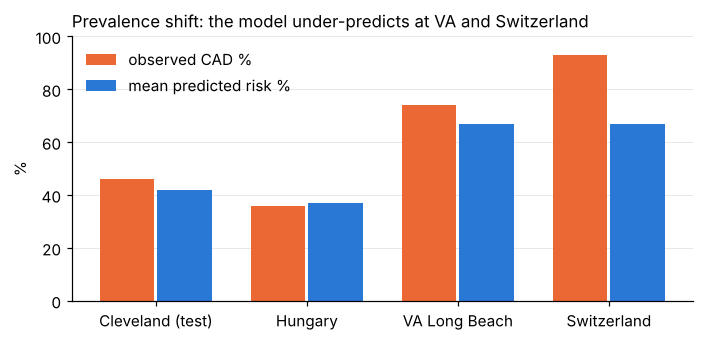

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(len(ext)); w = 0.36
ax.bar(x - w/2 - 0.01, ext.observed_CAD * 100, w, color=ORANGE, label="observed CAD %")
ax.bar(x + w/2 + 0.01, ext.mean_predicted * 100, w, color=BLUE, label="mean predicted risk %")
ax.set_xticks(x, ext.index); ax.set_ylim(0, 100); ax.set_ylabel("%")
ax.set_title("Prevalence shift: the model under-predicts at VA and Switzerland", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("figs/external_shift.png", dpi=200); plt.show()

**Reading.** Hungary (prevalence 36 %) behaves like Cleveland. At VA (74 %) and Switzerland (93 %) almost nobody is ruled out, and NPV collapses, because those populations are much sicker.
A rule-out tool is only safe in a population like the one it was validated in, so **recalibrate and re-validate before any new site**.

## 10 · Error analysis: who did we miss? (sealed test, false negatives)

In [14]:
fn = test.assign(risk=p_te.round(2), rule=np.where(baseline_rule(test) == 1, "refer", "rule out"))
fn = fn[(p_te < THR) & (y_te == 1)]
show = lambda d: d[["age","sex","cp","trestbps","num","risk","rule"]].assign(cp=lambda d: d.cp.map(CP), sex=lambda d: d.sex.map({0:"F",1:"M"}))
print("Sealed test, false negatives:"); display(show(fn))
fn_dev = dev.assign(risk=p_oof.round(2), rule=np.where(baseline_rule(dev) == 1, "refer", "rule out"))
fn_dev = fn_dev[(p_oof < THR) & (y_dev == 1)]
print("Development (out-of-fold), false negatives:"); display(show(fn_dev).sort_values("num", ascending=False))

Sealed test, false negatives:


,age,sex,cp,trestbps,num,risk,rule
211,38.0,M,typical angina,120.0,4,0.12,refer


Development (out-of-fold), false negatives:


,age,sex,cp,trestbps,num,risk,rule
261,58.0,F,atypical angina,136.0,3,0.06,refer
114,62.0,F,non-anginal,130.0,2,0.09,refer
301,57.0,F,atypical angina,130.0,1,0.06,refer
145,47.0,M,non-anginal,108.0,1,0.15,rule out
298,45.0,M,typical angina,110.0,1,0.14,refer


**Pattern.** The test-set miss is a 38-year-old man with **typical angina** and severe disease (`num` = 4), which the rule would have referred.
Because of referral bias, typical angina has a *lower* CAD rate than "asymptomatic" in this dataset, so the model learned to discount it: a label/selection artefact that becomes a clinical error.
In development, 3 of 5 misses are **women aged 57–62 with atypical/non-anginal pain**, all of whom the rule (age ≥ 55 → refer) would have caught. The model's large "female" discount outweighs age.
Fixes to test: **always refer typical angina and anyone ≥ 55** (hard safety rule on top of the model), plus safety-net advice for everyone ruled out.

## 11 · Prototype: nurse triage assistant
Run the cell and move the controls. The widget falls back to plain function calls if `ipywidgets` is not available.

In [15]:
coef = final.named_steps["logisticregression"].coef_[0]
names = final.named_steps["columntransformer"].get_feature_names_out()

def triage(age, sex, cp, bp, show=True):
    row = pd.DataFrame([dict(age=age, sex=sex, cp=cp, trestbps=bp)])
    p = final.predict_proba(row)[0, 1]
    rule = "REFER" if baseline_rule(row)[0] else "rule out"
    decision = "REFER for cardiology work-up" if p >= THR else "LOW RISK: routine follow-up + safety-net advice"
    z = final.named_steps["columntransformer"].transform(row)
    z = z.toarray()[0] if hasattr(z, "toarray") else z[0]
    contrib = sorted(zip(names, coef * z), key=lambda t: -abs(t[1]))[:3]
    why = ", ".join(f"{n.split('__')[1]} ({'+' if c > 0 else '−'})" for n, c in contrib)
    if show:
        print(f"Predicted CAD risk: {p:.0%}   (threshold {THR:.0%})")
        print(f"Model:  {decision}")
        print(f"Rule:   {rule}")
        print(f"Main drivers: {why}")
        print("⚠ Stable chest pain only. Acute pain, abnormal vitals or red flags → ACS pathway, not this tool.")
    return p

print("Demo case 1"); triage(48, 0, 2, 130); print()
print("Demo case 2"); triage(60, 1, 4, 140);

Demo case 1
Predicted CAD risk: 4%   (threshold 16%)
Model:  LOW RISK: routine follow-up + safety-net advice
Rule:   rule out
Main drivers: sex (−), cp_2.0 (−), age (−)
⚠ Stable chest pain only. Acute pain, abnormal vitals or red flags → ACS pathway, not this tool.

Demo case 2
Predicted CAD risk: 87%   (threshold 16%)
Model:  REFER for cardiology work-up
Rule:   REFER
Main drivers: cp_4.0 (+), sex (+), age (+)
⚠ Stable chest pain only. Acute pain, abnormal vitals or red flags → ACS pathway, not this tool.


In [16]:
try:
    import ipywidgets as W
    from IPython.display import display
    ui = dict(age=W.IntSlider(55, 29, 80, description="Age"),
              sex=W.ToggleButtons(options=[("Female", 0), ("Male", 1)], value=1, description="Sex"),
              cp=W.Dropdown(options=[(v, k) for k, v in CP.items()], value=2, description="Chest pain"),
              bp=W.IntSlider(130, 90, 200, step=2, description="Resting BP"))
    out = W.interactive_output(triage, ui)
    display(W.VBox(list(ui.values())), out)
except ImportError:
    print("ipywidgets not installed: call triage(age, sex, cp, bp) directly.")

Output()

## 12 · TwoKey design: the AI never rules out alone
Two safety layers built from what sections 8–10 taught us:
1. **Two keys.** A patient is ruled out only when **both** the model (risk < threshold) **and** the clinical rule say rule out. Any disagreement → refer, and the disagreement is logged for review. This also blocks the two failure modes we found (typical angina; women aged 55+).
2. **Site guard (one-way ratchet).** The clinic enters its local CAD rate among referred patients. Risks are shifted to that prevalence (prior-shift recalibration of the intercept), but **only upwards**: the tool may become more cautious than in development, never less.

In [17]:
logit = lambda p: np.log(p / (1 - p)); expit = lambda z: 1 / (1 + np.exp(-z))
PREV_DEV = y_dev.mean()
def site_guard(p, local_prev):
    shift = max(0.0, logit(local_prev) - logit(PREV_DEV))      # one-way: never less cautious
    return expit(logit(np.clip(p, 1e-6, 1 - 1e-6)) + shift)

rows = []
sets = {"Development (OOF)": (dev, y_dev, p_oof), "Cleveland test": (test, y_te, p_te)}
for s in ["Hungary", "VA Long Beach", "Switzerland"]:
    d = raw[s]; sets[s] = (d, d.y.values, final.predict_proba(d[TRIAGE])[:, 1])
for name, (d, y, p) in sets.items():
    rule_refer = baseline_rule(d).astype(bool)
    pg = site_guard(p, y.mean())
    for policy, refer in [("Model alone", p >= THR), ("Rule alone", rule_refer),
                          ("TwoKey", (p >= THR) | rule_refer), ("TwoKey + site guard", (pg >= THR) | rule_refer)]:
        m = rule_out_metrics(y, refer)
        rows.append(dict(site=name, policy=policy, sensitivity=m["sensitivity"], ruled_out=m["ruled_out"],
                         NPV=m["NPV"], missed_per_100=m["missed_per_100"]))
    agree_out = ~(p >= THR) & ~rule_refer
    print(f"{name:18s} disagreement {(((p >= THR) != rule_refer)).mean():.0%} · CAD rate when both keys say rule-out: "
          f"{y[agree_out].mean() if agree_out.any() else float('nan'):.2f} (n={agree_out.sum()})")
twokey = pd.DataFrame(rows).set_index(["site", "policy"]).round(2); twokey

Development (OOF)  disagreement 18% · CAD rate when both keys say rule-out: 0.03 (n=32)
Cleveland test     disagreement 20% · CAD rate when both keys say rule-out: 0.00 (n=15)
Hungary            disagreement 20% · CAD rate when both keys say rule-out: 0.07 (n=88)
VA Long Beach      disagreement 6% · CAD rate when both keys say rule-out: 0.00 (n=4)
Switzerland        disagreement 8% · CAD rate when both keys say rule-out: 0.33 (n=3)


sensitivity  ruled_out   NPV  missed_per_100
site              policy                                                           
Development (OOF) Model alone                 0.95       0.21  0.89            2.20
                  Rule alone                  0.96       0.25  0.93            1.76
                  TwoKey                      0.99       0.14  0.97            0.44
                  TwoKey + site guard         0.99       0.14  0.97            0.44
Cleveland test    Model alone                 0.97       0.29  0.95            1.32
                  Rule alone                  0.91       0.30  0.87            3.95
                  TwoKey                      1.00       0.20  1.00            0.00
                  TwoKey + site guard         1.00       0.20  1.00            0.00
Hungary           Model alone                 0.91       0.35  0.90            3.40
                  Rule alone                  0.89       0.45  0.91            4.08
                  TwoKey                      0.94       0.30  0.93            2.04
                  TwoKey + site guard         0.94       0.30  0.93            2.04
VA Long Beach     Model alone                 0.99       0.04  0.86            0.50
                  Rule alone                  0.96       0.07  0.57            3.00
                  TwoKey                      1.00       0.02  1.00            0.00
                  TwoKey + site guard         1.00       0.00   NaN            0.00
Switzerland       Model alone                 0.96       0.06  0.29            4.07
                  Rule alone                  0.95       0.07  0.33            4.88
                  TwoKey                      0.99       0.02  0.67            0.81
                  TwoKey + site guard         1.00       0.00   NaN            0.00

**Reading.** TwoKey trades rule-outs for safety: on the sealed test it rules out 20 % (vs 29 %) with **no missed CAD**. On development it misses 0.4 per 100 patients instead of about 2.
The site guard does what a human should: at VA and Switzerland it **turns rule-out off by itself** (0 % ruled out, so nobody is falsely reassured), while Hungary keeps the development calibration because the ratchet never relaxes.
**Caution:** TwoKey was designed *after* we saw the error cases, including the one test-set miss, so the Cleveland test row is no longer an unbiased check. **Hungary is the fair test** (never used for design): TwoKey raises sensitivity from 0.91 to 0.94 and NPV from 0.90 to 0.93, ruling out 30 % instead of 35 %.
In practice the local CAD rate would come from last month's audit, not from the test labels; here we use each site's observed rate to show the mechanism.

## 13 · Limitations and path to practice
- **Label bias:** only angiography-referred patients were labelled. Real triage prevalence is lower, so NPV would be higher but sensitivity is unverified.
- **Moment of use:** we excluded exercise-test, fluoroscopy and thallium features; published 0.90 AUROCs are not achievable at triage.
- **Is AI needed?** Alone, the LR does **not** beat a two-item rule. Used as a second key with the rule (TwoKey), the pair is safer than either alone; that, not a better AUROC, is where the model earns its place.
- **Shift:** fails at VA and Switzerland (prevalence 74–93 %). Data are from 1980s USA/Europe, not Thai patients.
- **Evidence ladder:** we stand on rung 1 (internal) with a partial rung 2 (other sites). **Next rung:** retrospective external validation on Thai OPD chest-pain patients, then a silent trial.
- **Reporting:** TRIPOD+AI for development/validation; PROBAST for risk-of-bias self-check.
- **SaMD / IMDRF:** drives the nurse's triage decision for a serious condition → IMDRF category II; the nurse can always override.
- **Monitoring / switch-off:** track monthly referral rate, missed CAD found at follow-up, and predicted vs observed prevalence. Switch off if sensitivity on audit falls below 90 % or the case mix shifts; the cardiology lead owns the off switch.